# 07. Sharpe ratio of each bank against the IHSG (H3), and the market-implied return

**Why this notebook exists.** The main research question asks whether the banks delivered better risk-adjusted returns than the IHSG. Overlapping confidence intervals for two Sharpe ratios do not answer that: the bank and the index trade on the same days and are correlated, so the interval for their *difference* can be much narrower than either interval. This notebook tests the difference directly. The test was added on 2026-10-19, after a methodological review of the first draft, as hypothesis H3.

**H3.** For each bank, Sharpe(bank) − Sharpe(IHSG) = 0, two-sided, on excess returns over the policy rate (price returns).
- **Primary family:** the full period, three tests, with a Holm adjustment across the three.
- **Secondary:** R1, R2 and R3 (nine more tests), with a Holm adjustment across all twelve. The Stub is excluded.

**Method: Ledoit and Wolf (2008), studentized circular block bootstrap** (`metrics.ledoit_wolf_sharpe_test`).
- Resamples whole blocks of consecutive days for the bank and the index together, so the days stay paired and short-run dependence is kept.
- Each resample has its own standard error, and the interval is symmetric and studentized.
- The p-value follows Remark 3.2 of the paper.
- Settings: 10,000 resamples, block size 10 days (5 and 21 as sensitivity), fixed seed.
- **Two simplifications against the paper, stated in the report:**
  - a Bartlett (Newey–West) kernel for the standard error of the original data instead of the prewhitened quadratic-spectral kernel;
  - a fixed block size instead of the paper's calibration algorithm.

**Second part: how much of each bank's return the market exposure implies.** For each bank and period, the return a holder would have earned from the risk-free rate plus the estimated beta times the IHSG excess return, compounded, is compared with the bank's actual return. The gap is what the market exposure does not account for. This puts the R3 divergence in percentage points.

**How to run.** Select the project `.venv` kernel, then *Restart* and *Run All*. The notebook asks for the PostgreSQL user and password. It only reads from the database. The bootstrap takes a few minutes.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
try:
    import db_access
    import metrics
    from statsmodels.stats.multitest import multipletests
except ImportError as exc:
    raise ImportError(
        f"{exc}\nThis kernel is {sys.executable}. Select the project .venv kernel "
        "(top right of the notebook, Select Kernel > Python Environments > .venv), then Restart and Run All."
    ) from exc

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("project root:", ROOT)

project root: d:\Data Analyst\Portfolio


## 1. Load the data

Two reads, both `SELECT` only.

In [2]:
conn = db_access.connect()
try:
    prices = db_access.load_prices(conn)
    sql = db_access.load_excess_returns(conn)
finally:
    conn.close()

print("prices rows:", len(prices), "| SQL view rows:", len(sql))

prices rows: 5536 | SQL view rows: 5524


## 2. Settings and returns

The same construction as notebooks 02 and 03: simple returns from `close`, daily risk-free rate = policy rate / 100 / 252, excess return = return minus that rate.

In [3]:
BANKS = ["BBCA", "BBRI", "BMRI"]
MARKET = "IHSG"
TICKERS = BANKS + [MARKET]
FIRST_RETURN_DAY = pd.Timestamp("2021-01-04")
EXPECTED_DAYS = 1381
REGIME_DAYS = {"R1": 399, "R2": 499, "R3": 393, "Stub": 90}
PERIODS = ["Full", "R1", "R2", "R3"]
N_BOOT = 10_000
BLOCK = 10
SENSITIVITY_BLOCKS = (5, 21)
SEED = 20260101
LEVEL = 0.95
RET_TOL = 1e-12

COLORS = {"BBCA": "#2a78d6", "BBRI": "#eb6834", "BMRI": "#1baf7a", "IHSG": "#52514e"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d3"

results = []


def check(name, ok, detail=""):
    results.append(bool(ok))
    print(f"{'PASS' if ok else 'FAIL'}  {name}" + (f"  [{detail}]" if detail else ""))


close = db_access.to_wide(prices, "close")[TICKERS]
ret = metrics.simple_returns(close, FIRST_RETURN_DAY)
rate = sql.drop_duplicates("trade_date").set_index("trade_date")["rate_pct"].sort_index()
rf = metrics.daily_risk_free(rate).reindex(ret.index)
excess = metrics.excess_return(ret, rf)

labels = metrics.assign_regime(ret.index)
period_days = {"Full": ret.index}
period_days.update({name: ret.index[labels == name] for name in REGIME_DAYS})

sql_excess = db_access.to_wide(sql, "excess_close")[TICKERS]
check(f"{EXPECTED_DAYS} return days, no missing values", len(ret) == EXPECTED_DAYS and not excess.isna().any().any())
check("excess returns equal the SQL view", (excess - sql_excess).abs().max().max() < RET_TOL)
check("regime day counts", all(len(period_days[r]) == n for r, n in REGIME_DAYS.items()), str(REGIME_DAYS))

PASS  1381 return days, no missing values
PASS  excess returns equal the SQL view
PASS  regime day counts  [{'R1': 399, 'R2': 499, 'R3': 393, 'Stub': 90}]


## 3. H3: Sharpe(bank) − Sharpe(IHSG)

One test per bank and period, at block size 10, with the p-values at block sizes 5 and 21 as sensitivity and the plain HAC (normal-approximation) p-value of the paper's section 3.1 for comparison. Each test uses its own seed derived from the period, so the same resampled days are used for the three banks within a period.

The Sharpe ratios in this table use population moments (divide by T), as in the paper, so they are larger in size than those in notebook 02 by the factor √(T / (T − 1)): at most 0.13% (R3).

In [4]:
rows = []
for k, period in enumerate(PERIODS):
    days = period_days[period]
    for t in BANKS:
        main = metrics.ledoit_wolf_sharpe_test(excess.loc[days, t], excess.loc[days, MARKET],
                                               block=BLOCK, n_boot=N_BOOT, seed=SEED + k, level=LEVEL)
        row = {"period": period, "ticker": t, "n": main["n"], "sharpe_bank": main["sharpe_i"], "sharpe_ihsg": main["sharpe_n"],
               "delta": main["delta"], "ci_low": main["ci_low"], "ci_high": main["ci_high"], "p_value": main["p_value"],
               "p_hac_normal": main["p_hac_normal"], "hac_lags": main["lags"]}
        for b in SENSITIVITY_BLOCKS:
            row[f"p_block{b}"] = metrics.ledoit_wolf_sharpe_test(excess.loc[days, t], excess.loc[days, MARKET],
                                                                 block=b, n_boot=N_BOOT, seed=SEED + k, level=LEVEL)["p_value"]
        rows.append(row)
h3 = pd.DataFrame(rows).set_index(["period", "ticker"])

full = h3.index.get_level_values("period") == "Full"
h3["holm_full_family"] = np.nan
h3.loc[full, "holm_full_family"] = multipletests(h3.loc[full, "p_value"], method="holm")[1]
h3["holm_all_12"] = multipletests(h3["p_value"], method="holm")[1]
h3["excludes_0"] = (h3["ci_low"] > 0) | (h3["ci_high"] < 0)
h3.round(4)

n  sharpe_bank  sharpe_ihsg   delta  ci_low  ci_high  p_value  p_hac_normal  hac_lags  p_block5  p_block21  holm_full_family  holm_all_12  excludes_0
period ticker                                                                                                                                                          
Full   BBCA    1381      -0.1483      -0.1990  0.0507 -0.6915   0.7930   0.8958        0.8904         7    0.8925     0.8950               1.0          1.0       False
       BBRI    1381      -0.1344      -0.1990  0.0646 -0.6560   0.7852   0.8604        0.8572         7    0.8586     0.8507               1.0          1.0       False
       BMRI    1381       0.1333      -0.1990  0.3323 -0.4354   1.1000   0.3859        0.3788         7    0.3792     0.3948               1.0          1.0       False
R1     BBCA     399       0.4173       0.6028 -0.1854 -1.5754   1.2046   0.7895        0.7789         5    0.7808     0.7795               NaN          1.0       False
       BBRI     399       0.2824       0.6028 -0.3203 -1.5469   0.9062   0.5975        0.5862         5    0.5985     0.6071               NaN          1.0       False
       BMRI     399       0.6699       0.6028  0.0672 -1.3679   1.5023   0.9258        0.9209         5    0.9206     0.9265               NaN          1.0       False
R2     BBCA     499       0.5086      -0.0181  0.5268 -0.6094   1.6630   0.3557        0.3470         5    0.3465     0.3659               NaN          1.0       False
       BBRI     499       0.3368      -0.0181  0.3549 -0.8826   1.5925   0.5671        0.5560         5    0.5633     0.5825               NaN          1.0       False
       BMRI     499       0.9868      -0.0181  1.0050 -0.2661   2.2760   0.1209        0.1087         5    0.1152     0.1322               NaN          1.0       False
R3     BBCA     393      -1.3109      -0.7706 -0.5402 -2.1565   1.0761   0.5049        0.4911         5    0.4934     0.5188               NaN          1.0       False
       BBRI     393      -1.0292      -0.7706 -0.2586 -1.7736   1.2564   0.7313        0.7173         5    0.7156     0.7284               NaN          1.0       False
       BMRI     393      -1.0238      -0.7706 -0.2531 -1.8054   1.2992   0.7339        0.7332         5    0.7342     0.7475               NaN          1.0       False

In [5]:
nb02 = {(p, t): metrics.sharpe_ratio(excess.loc[period_days[p], t]) for p in PERIODS for t in TICKERS}
factor = {p: np.sqrt(len(period_days[p]) / (len(period_days[p]) - 1)) for p in PERIODS}
factor_ok = all(abs(h3.loc[(p, t), "sharpe_bank"] - nb02[(p, t)] * factor[p]) < 1e-10
                and abs(h3.loc[(p, t), "sharpe_ihsg"] - nb02[(p, MARKET)] * factor[p]) < 1e-10
                for p in PERIODS for t in BANKS)
check("the test's Sharpe ratios equal notebook 02's times sqrt(T / (T - 1))", factor_ok)
check("each interval contains its estimated difference", ((h3["ci_low"] < h3["delta"]) & (h3["delta"] < h3["ci_high"])).all())

swap = metrics.ledoit_wolf_sharpe_test(excess[MARKET], excess["BBCA"], block=BLOCK, n_boot=N_BOOT, seed=SEED, level=LEVEL)
check("swapping bank and index flips the sign and keeps the p-value (BBCA, full period)",
      abs(swap["delta"] + h3.loc[("Full", "BBCA"), "delta"]) < 1e-12 and abs(swap["p_value"] - h3.loc[("Full", "BBCA"), "p_value"]) < 1e-12)

agree = int((h3["excludes_0"] == (h3["p_value"] < 0.05)).sum())
print(f"interval verdict and p-value verdict agree in {agree} of {len(h3)} tests (they can differ only right at the 5% boundary)")
for label, col in (("full-period family (3 tests)", "holm_full_family"), ("all 12 tests", "holm_all_12")):
    print(f"below 0.05 after Holm, {label}: {int((h3[col] < 0.05).sum())}")
print("unadjusted p below 0.05 at block 10:", int((h3["p_value"] < 0.05).sum()), "of", len(h3))

PASS  the test's Sharpe ratios equal notebook 02's times sqrt(T / (T - 1))
PASS  each interval contains its estimated difference
PASS  swapping bank and index flips the sign and keeps the p-value (BBCA, full period)
interval verdict and p-value verdict agree in 12 of 12 tests (they can differ only right at the 5% boundary)
below 0.05 after Holm, full-period family (3 tests): 0
below 0.05 after Holm, all 12 tests: 0
unadjusted p below 0.05 at block 10: 0 of 12


## 4. Figure 8: the differences with their intervals

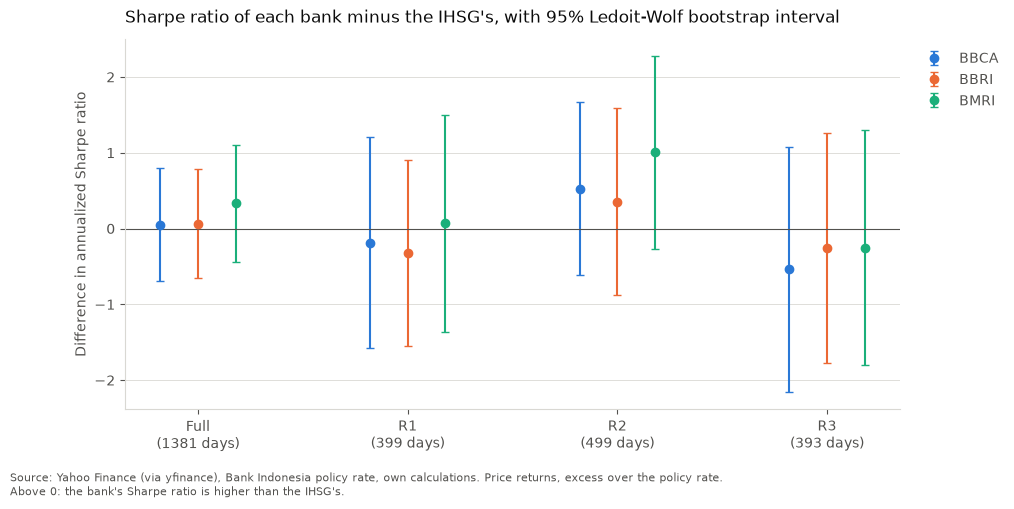

PASS  figure 8 was written


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for j, t in enumerate(BANKS):
    x = np.arange(len(PERIODS)) + (j - 1) * 0.18
    v = np.array([h3.loc[(p, t), "delta"] for p in PERIODS])
    lo = np.array([h3.loc[(p, t), "ci_low"] for p in PERIODS])
    hi = np.array([h3.loc[(p, t), "ci_high"] for p in PERIODS])
    ax.errorbar(x, v, yerr=[v - lo, hi - v], fmt="o", ms=6, lw=1.5, capsize=3, color=COLORS[t], label=t)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(range(len(PERIODS)))
ax.set_xticklabels([f"{p}\n({len(period_days[p])} days)" for p in PERIODS])
ax.set_title("Sharpe ratio of each bank minus the IHSG's, with 95% Ledoit-Wolf bootstrap interval", loc="left", fontsize=12, color=INK, pad=12)
ax.set_ylabel("Difference in annualized Sharpe ratio", color=MUTED)
ax.grid(axis="y", color=GRID, lw=0.6)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(GRID)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0), labelcolor=MUTED)
fig.text(0.01, -0.02, "Source: Yahoo Finance (via yfinance), Bank Indonesia policy rate, own calculations. Price returns, excess over the policy rate.\n"
         "Above 0: the bank's Sharpe ratio is higher than the IHSG's.", fontsize=8, color=MUTED, ha="left", va="top")
fig_dir = ROOT / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
fig_path = fig_dir / "fig8_sharpe_difference.png"
fig.savefig(fig_path, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
check("figure 8 was written", fig_path.exists() and fig_path.stat().st_size > 10_000)

## 5. Market-implied return against actual return

For each bank and period, beta is estimated on that period's excess returns (as in notebook 03). Then:
- **actual:** Π(1 + r_bank) − 1, the bank's price return;
- **market-implied:** Π(1 + rf + β · e_IHSG) − 1, what the risk-free rate plus the estimated market exposure would have produced;
- **gap:** actual minus market-implied, in percentage points. It is the part of the return that the market exposure does not account for (the intercept and the residuals, compounded).

The identity check rebuilds the actual return exactly from rf + α + β · e_IHSG + residual, which confirms the decomposition adds up. The gap is descriptive: it is not tested, and its size is uncertain for the same reason the intercepts are imprecise.

In [7]:
rows = []
for period, days in period_days.items():
    if period == "Stub":
        continue
    for t in BANKS:
        e_b, e_m, r_f = excess.loc[days, t], excess.loc[days, MARKET], rf.loc[days]
        c = metrics.capm(e_b, e_m)
        resid = e_b - c["alpha"] - c["beta"] * e_m
        actual = float(np.prod(1 + ret.loc[days, t]) - 1)
        implied = float(np.prod(1 + r_f + c["beta"] * e_m) - 1)
        rebuilt = float(np.prod(1 + r_f + c["alpha"] + c["beta"] * e_m + resid) - 1)
        rows.append({"period": period, "ticker": t, "beta": c["beta"], "ihsg_return_pct": 100 * float(np.prod(1 + ret.loc[days, MARKET]) - 1),
                     "actual_pct": 100 * actual, "market_implied_pct": 100 * implied, "gap_pct_points": 100 * (actual - implied),
                     "rebuilt_pct": 100 * rebuilt})
implied_tbl = pd.DataFrame(rows).set_index(["period", "ticker"])
check("actual return is rebuilt exactly from rf + alpha + beta * market + residual", (implied_tbl["actual_pct"] - implied_tbl["rebuilt_pct"]).abs().max() < 1e-9)
implied_tbl.drop(columns="rebuilt_pct").round(2)

PASS  actual return is rebuilt exactly from rf + alpha + beta * market + residual


beta  ihsg_return_pct  actual_pct  market_implied_pct  gap_pct_points
period ticker                                                                       
Full   BBCA    0.94             1.54      -10.27                3.67          -13.94
       BBRI    1.14             1.54      -17.17               -3.23          -13.94
       BMRI    1.17             1.54       26.80               -4.22           31.02
R1     BBCA    1.06            18.88       18.17               19.56           -1.39
       BBRI    1.34            18.88       12.64               22.83          -10.19
       BMRI    1.32            18.88       34.78               22.59           12.19
R2     BBCA    0.96            10.18       31.25               10.31           20.94
       BBRI    1.36            10.18       24.12                8.97           15.15
       BMRI    1.45            10.18       74.19                8.61           65.58
R3     BBCA    0.82           -18.66      -43.33              -13.97          -29.37
       BBRI    1.04           -18.66      -42.64              -19.66          -22.99
       BMRI    1.06           -18.66      -44.38              -20.23          -24.15

## 6. Summary and saved tables

Every check above must print PASS.

In [8]:
out = ROOT / "reports"
h3.to_csv(out / "07_sharpe_difference.csv")
implied_tbl.drop(columns="rebuilt_pct").to_csv(out / "07_market_implied_returns.csv")

n_fail = results.count(False)
print(f"{len(results) - n_fail} passed, {n_fail} failed")
assert n_fail == 0, "At least one check failed. Investigate before using these tables."

8 passed, 0 failed
